# Regressão linear no dataset MedPT (TP3)

Aqui eu uso regressão linear só como exercício, mesmo a tarefa final do projeto sendo de classificação. A variável alvo que escolhi foi o **tamanho da resposta em palavras** (`tam_resposta`), e as variáveis de entrada vêm da pergunta do paciente.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("medpt_amostra.csv")
df.shape

(5000, 6)

## 1. Variáveis derivadas

In [2]:
df["tam_pergunta"] = df["question"].str.split().str.len()
df["tam_resposta"] = df["answer"].astype(str).str.split().str.len()
df["palavras_unicas"] = df["question"].apply(lambda x: len(set(x.lower().split())))
df["num_interrogacoes"] = df["question"].str.count(r"\?")
df[["tam_pergunta", "tam_resposta", "palavras_unicas", "num_interrogacoes"]].describe()

,tam_pergunta,tam_resposta,palavras_unicas,num_interrogacoes
count,5000.000000,5000.000000,5000.000000,5000.000000
mean,29.298000,54.127600,25.752800,1.182000
std,19.606348,39.351399,15.318323,0.646343
min,3.000000,4.000000,3.000000,0.000000
25%,14.000000,28.000000,13.000000,1.000000
50%,24.000000,45.000000,22.000000,1.000000
75%,42.000000,69.000000,36.000000,1.000000
max,164.000000,435.000000,119.000000,8.000000


## 2. Separação treino/teste

Cada pergunta aparece várias vezes no dataset (uma por resposta de médico diferente). Se eu separasse as linhas aleatoriamente, a mesma pergunta cairia no treino e no teste e o resultado ficaria artificialmente bom. Por isso usei `GroupShuffleSplit` agrupando pela pergunta.

In [3]:
y = df["tam_resposta"]
grupos = df["question"]
idx_treino, idx_teste = next(GroupShuffleSplit(test_size=0.2, random_state=42).split(df, y, grupos))
treino, teste = df.iloc[idx_treino], df.iloc[idx_teste]
len(treino), len(teste)

(4063, 937)

## 3. Regressão linear simples (só `tam_pergunta`)

In [4]:
simples = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", LinearRegression()),
])
simples.fit(treino[["tam_pergunta"]], treino["tam_resposta"])
pred_simples = simples.predict(teste[["tam_pergunta"]])

r2_s = r2_score(teste["tam_resposta"], pred_simples)
rmse_s = mean_squared_error(teste["tam_resposta"], pred_simples) ** 0.5
print("R2:", round(r2_s, 4))
print("RMSE:", round(rmse_s, 2))

R2: 0.0029
RMSE: 36.34


## 4. Regressão linear múltipla

In [5]:
numericas = ["tam_pergunta", "palavras_unicas", "num_interrogacoes"]
categoricas = ["question_type"]

pre = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(drop="first"), categoricas),
])

multipla = Pipeline([
    ("pre", pre),
    ("modelo", LinearRegression()),
])
multipla.fit(treino[numericas + categoricas], treino["tam_resposta"])
pred_mult = multipla.predict(teste[numericas + categoricas])

r2_m = r2_score(teste["tam_resposta"], pred_mult)
rmse_m = mean_squared_error(teste["tam_resposta"], pred_mult) ** 0.5
print("R2:", round(r2_m, 4))
print("RMSE:", round(rmse_m, 2))

R2: 0.0061
RMSE: 36.28


In [6]:
pd.DataFrame({
    "modelo": ["simples", "múltipla"],
    "R2": [r2_s, r2_m],
    "RMSE": [rmse_s, rmse_m],
}).round(4)

,modelo,R2,RMSE
0,simples,0.0029,36.3394
1,múltipla,0.0061,36.2812


## 5. Análise dos resíduos (modelo múltiplo)

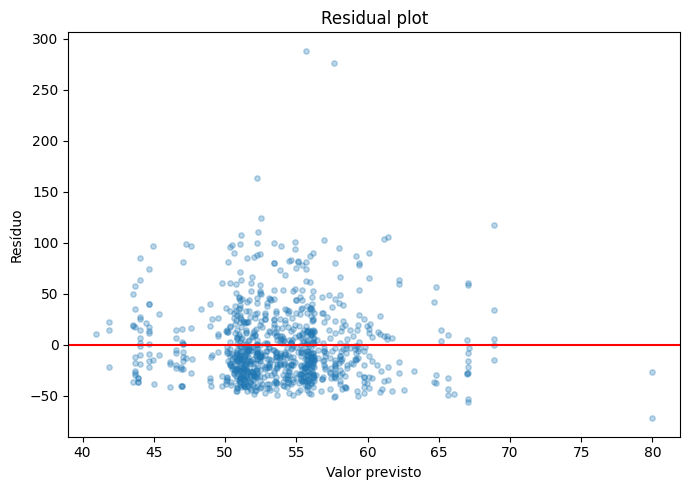

In [7]:
residuos = teste["tam_resposta"].values - pred_mult

plt.figure(figsize=(7, 5))
plt.scatter(pred_mult, residuos, alpha=0.3, s=15)
plt.axhline(0, color="red")
plt.xlabel("Valor previsto")
plt.ylabel("Resíduo")
plt.title("Residual plot")
plt.tight_layout()
plt.savefig("residual_plot.png")
plt.show()

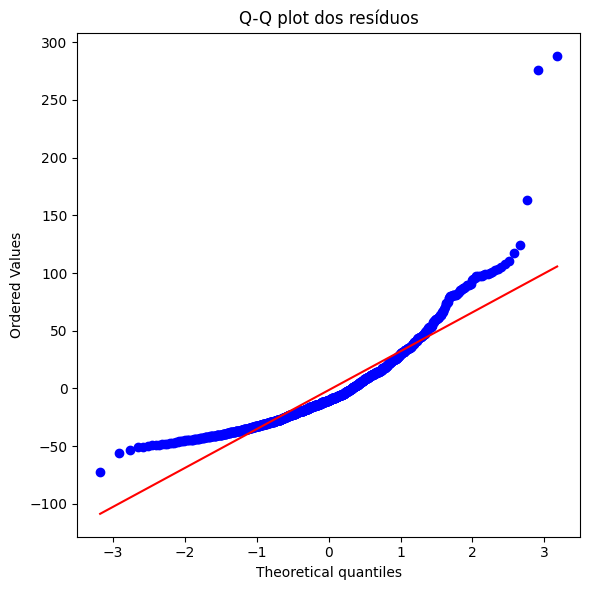

assimetria dos resíduos: 1.99


In [8]:
plt.figure(figsize=(6, 6))
stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q plot dos resíduos")
plt.tight_layout()
plt.savefig("qq_plot.png")
plt.show()

print("assimetria dos resíduos:", round(stats.skew(residuos), 2))

## 6. Limitações e próximos passos

**O que os números mostram:** os dois modelos têm R² praticamente zero. O tamanho da pergunta (e as outras variáveis que usei) quase não explica o tamanho da resposta, o que já aparecia na correlação de 0,09 do TP2. Adicionar mais variáveis (modelo múltiplo) melhorou muito pouco.

**Limitações que eu identifiquei:**
- No residual plot, as previsões ficam concentradas numa faixa estreita (entre uns 43 e 69 palavras), ou seja, o modelo prevê quase sempre um valor parecido com a média. Os resíduos ficam em sua maioria negativos, com alguns positivos bem grandes, então eles não estão distribuídos de forma simétrica em volta do zero.
- No Q-Q plot a cauda direita sobe bem acima da reta: existem respostas muito longas (até 435 palavras) que o modelo não consegue prever, e os resíduos não seguem uma distribuição normal (têm assimetria positiva).
- As variáveis de entrada são todas medidas de tamanho de texto, que não carregam o conteúdo médico da pergunta. O que determina o tamanho da resposta provavelmente é o assunto e o estilo de cada médico.
- As respostas de médicos diferentes para a mesma pergunta variam muito, então existe muito ruído que nenhuma variável da pergunta consegue explicar.

**Próximos passos:**
- Usar o conteúdo do texto (TF-IDF) como entrada em vez de só contagens de tamanho.
- Testar a transformação logarítmica do alvo para reduzir a assimetria dos resíduos.
- Seguir para o problema de classificação da intenção (`question_type`), que é o objetivo real do projeto e onde o texto da pergunta tem muito mais informação útil.